In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns

In [6]:
# base_filepath = '/Volumes/mrsic_flogel/public/projects/SaReSuKu_20240722_HeadFixedSchemaImaging/rawdata/sub-TAA0000117/ses-001/funcimg/910nm/20250624_151550__TAA0000117_00001/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_corrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/striped_distortion_uncorrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg/destriped_distortion_corrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg/striped_distortion_uncorrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg/destriped_distortion_uncorrected/suite2p/'
# base_filepath = '/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/sub-01_id-M14/ses-02_date-20260506/funcimg/suite2p/'
base_filepath = '/Users/megyoung/Desktop/mfh lab meeting/ex2/suite2p/'
proc_path = 'plane0/'
file = 'ops.npy'

dict_keys(['data_path', 'look_one_level_down', 'input_format', 'keep_movie_raw', 'nplanes', 'nchannels', 'swap_order', 'functional_chan', 'ignore_flyback', 'save_path0', 'fast_disk', 'save_folder', 'h5py_key', 'nwb_series', 'force_sktiff', 'batch_size', 'file_list', 'first_files', 'save_path', 'settings_path', 'db_path', 'reg_file', 'iplane', 'reg_file_chan2', 'Ly', 'Lx', 'nframes', 'frames_per_file', 'frames_per_folder', 'meanImg', 'meanImg_chan2', 'torch_device', 'tau', 'fs', 'diameter', 'run', 'io', 'registration', 'detection', 'classification', 'extraction', 'dcnv_preprocess', 'version', 'date_proc', 'refImg', 'rmin', 'rmax', 'yoff', 'xoff', 'corrXY', 'yoff1', 'xoff1', 'corrXY1', 'badframes', 'badframes0', 'yrange', 'xrange', 'bidiphase', 'meanImgE', 'plane_times'])


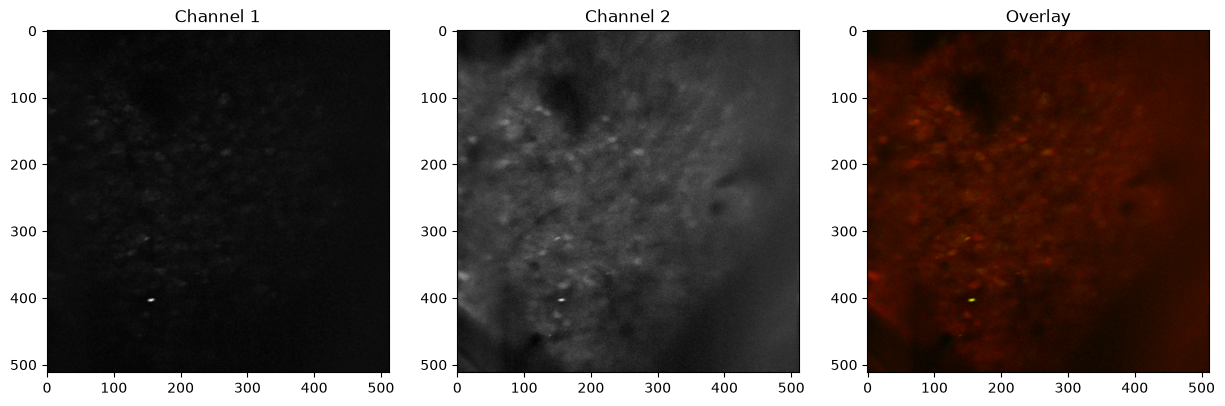

In [7]:
settings = np.load(os.path.join(base_filepath, proc_path, file), allow_pickle=True).item()
print(settings.keys())
img1 = settings['meanImg']
img2 = settings['meanImg_chan2']
#make an image overlay with the two channels
img1 = np.squeeze(img1)
img2 = np.squeeze(img2)
# Normalize images
img1 = (img1 - np.min(img1)) / (np.max(img1) - np.min(img1))
img2 = (img2 - np.min(img2)) / (np.max(img2) - np.min(img2))
# Create an overlay image
#img1 is the green channel, img2 is the red channel
img_overlay = np.zeros((img1.shape[0], img1.shape[1], 3), dtype=np.float32)
img_overlay[..., 0] = img2  # Red channel
img_overlay[..., 1] = img1  # Green channel

img_overlay[..., 0] = img2  # Red channel
img_overlay[..., 1] = img1 # Green channel

fig, (ax1,ax2,ax3) = plt.subplots(1, 3, figsize=(15, 10))
ax1.imshow(img1, cmap='gray')
ax2.imshow(img2, cmap='gray')   
# Display the overlay image as an RGB image
ax3.imshow(img_overlay)
ax1.set_title('Channel 1')
ax2.set_title('Channel 2')
ax3.set_title('Overlay')
plt.show()

## Interactive channel 1 contrast

Use the black percentile to darken the background, the white percentile to control bright-pixel saturation, and gamma to adjust midtones. A small isolated bright spot can be allowed to saturate by lowering the white percentile. These controls affect display only and do not modify Suite2p's data.

In [ ]:
# If this import fails, run: %pip install ipywidgets
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display

mean_ch1_raw = np.squeeze(np.asarray(settings["meanImg"], dtype=np.float32))

def scale_contrast(image, black_percentile, white_percentile, gamma):
    black, white = np.percentile(image[np.isfinite(image)], [black_percentile, white_percentile])
    if white <= black:
        raise ValueError("White percentile must produce a value above the black percentile")
    scaled = np.clip((image - black) / (white - black), 0, 1) ** gamma
    return scaled, black, white

black_slider = widgets.FloatSlider(
    value=10.0, min=0.0, max=50.0, step=0.5, description="Black %",
    continuous_update=False, readout_format=".1f",
)
white_slider = widgets.FloatSlider(
    value=99.95, min=90.0, max=100.0, step=0.05, description="White %",
    continuous_update=False, readout_format=".2f",
)
gamma_slider = widgets.FloatSlider(
    value=1.2, min=0.2, max=3.0, step=0.05, description="Gamma",
    continuous_update=False, readout_format=".2f",
)

def preview_contrast(black_percentile, white_percentile, gamma):
    if white_percentile <= black_percentile:
        print("White percentile must be greater than black percentile")
        return
    display_image, black, white = scale_contrast(
        mean_ch1_raw, black_percentile, white_percentile, gamma
    )
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    axes[0].imshow(display_image, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(
        f"Channel 1 | black={black:.3g}, white={white:.3g}, gamma={gamma:.2f}"
    )
    axes[0].axis("off")
    sample = mean_ch1_raw.ravel()[::max(1, mean_ch1_raw.size // 200_000)]
    axes[1].hist(sample[np.isfinite(sample)], bins=256, color="0.35")
    axes[1].axvline(black, color="tab:blue", label="black")
    axes[1].axvline(white, color="tab:red", label="white")
    axes[1].set_yscale("log")
    axes[1].set_title("Raw channel 1 intensity histogram")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

controls = widgets.VBox([black_slider, white_slider, gamma_slider])
preview = widgets.interactive_output(
    preview_contrast,
    {
        "black_percentile": black_slider,
        "white_percentile": white_slider,
        "gamma": gamma_slider,
    },
)
display(controls, preview)

Output()

In [11]:
# Run this cell after choosing the slider values to save exactly that display.
img1_contrast, black_value, white_value = scale_contrast(
    mean_ch1_raw, black_slider.value, white_slider.value, gamma_slider.value
)
contrast_output_path = Path(base_filepath) / proc_path / "meanImg_ch1_contrast.png"
plt.imsave(contrast_output_path, img1_contrast, cmap="gray", vmin=0, vmax=1)
print(f"Saved: {contrast_output_path}")
print(
    f"Black percentile={black_slider.value:g} (value={black_value:.3g}), "
    f"white percentile={white_slider.value:g} (value={white_value:.3g}), "
    f"gamma={gamma_slider.value:g}"
)

Saved: /Users/megyoung/Desktop/mfh lab meeting/ex2/suite2p/plane0/meanImg_ch1_contrast.png
Black percentile=1 (value=24.5), white percentile=99.95 (value=101), gamma=1


In [23]:
print("nchannels:", settings.get("nchannels"))
print("functional_chan:", settings.get("functional_chan"))
print("align_by_chan:", settings.get("align_by_chan"))

print("\nKeys containing 'chan':")
for k in sorted(settings.keys()):
    if "chan" in k.lower():
        print(k)

nchannels: 2
functional_chan: 2
align_by_chan: None

Keys containing 'chan':
functional_chan
meanImg_chan2
nchannels
reg_file_chan2


In [24]:
from pathlib import Path

plane0 = Path(base_filepath) / proc_path

for path in sorted(plane0.iterdir()):
    if path.suffix == ".bin" or "chan" in path.name.lower():
        print(path.name)

data.bin
data_chan2.bin


In [25]:
save_ch1_name = 'meanImg_ch1.tiff'
plt.imsave(os.path.join(base_filepath, proc_path, save_ch1_name), img1, cmap='gray')

save_ch2_name = 'meanImg_ch2.tiff'
plt.imsave(os.path.join(base_filepath, proc_path, save_ch2_name), img2, cmap='gray')

save_overlay_name = 'meanImg_overlay.tiff'
# plt.imsave(os.path.join(base_filepath, proc_path, save_overlay_name), img_overlay)

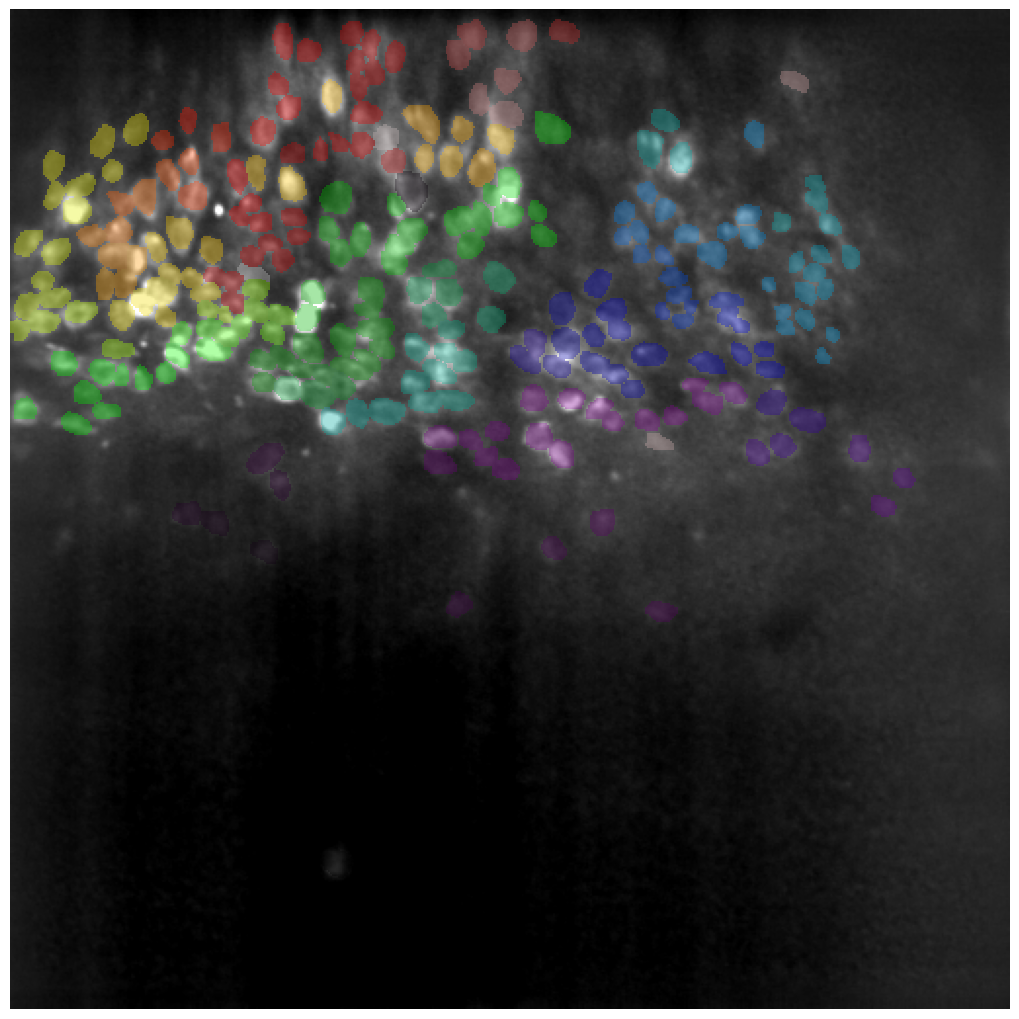

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# seg_path = Path("/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg/destriped_distortion_uncorrected/suite2p/plane0/meanImg_ch1_seg.npy")
seg_path = Path("/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/plane0/meanImg_ch1_seg.npy")
output_path = seg_path.with_name("meanImg_ch1_cp_masks (1).png")

seg = np.load(seg_path, allow_pickle=True).item()

masks = np.asarray(seg["masks"])

# meanImg belongs to Suite2p's ops.npy, not the Cellpose *_seg.npy file.
ops_path = seg_path.with_name("ops.npy")
ops = np.load(ops_path, allow_pickle=True).item()
mean_image = np.asarray(ops["meanImg"])  # Suite2p channel 1

# Remove RGB/channel dimension if Cellpose stored a grayscale image as RGB
if mean_image.ndim == 3:
    mean_image = mean_image[..., 0]

if mean_image.shape != masks.shape:
    raise ValueError(
        f"Shape mismatch: meanImg is {mean_image.shape}, masks are {masks.shape}"
    )

# Fiji-like display scaling for the background image
black, white = np.percentile(mean_image, [10, 99.8])
display_image = np.clip((mean_image - black) / (white - black), 0, 1)

# Hide label 0 so the background remains transparent
overlay = np.ma.masked_where(masks == 0, masks)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(display_image, cmap="gray")
ax.imshow(overlay, cmap="nipy_spectral", alpha=0.35, interpolation="none")
ax.axis("off")

plt.tight_layout(pad=0)
fig.savefig(output_path, dpi=200, bbox_inches="tight", pad_inches=0)
plt.show()